<a href="https://colab.research.google.com/github/hadiabatool-ai/sign-language-to-speech-converter/blob/main/ASL_Sign_Language_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 0:  Mount Google Drive
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Cell 1:  Unzip the ASL dataset from Drive
import zipfile
import os

zip_path = "/content/drive/MyDrive/ASL_Project/asl-alphabet.zip"

extract_path = "/content/asl_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
# Cell 2:  List the main folders (train and test)
print("Main folders:")

for item in os.listdir(extract_path):
    print(item)

Main folders:
asl_alphabet_test
asl_alphabet_train


In [4]:
# Cell 3:  Walk through the folder structure
for root, dirs, files in os.walk(extract_path):
    print("Folder:", root)
    print("Subfolders:", dirs[:10])
    print()

Folder: /content/asl_dataset
Subfolders: ['asl_alphabet_test', 'asl_alphabet_train']

Folder: /content/asl_dataset/asl_alphabet_test
Subfolders: ['asl_alphabet_test']

Folder: /content/asl_dataset/asl_alphabet_test/asl_alphabet_test
Subfolders: []

Folder: /content/asl_dataset/asl_alphabet_train
Subfolders: ['asl_alphabet_train']

Folder: /content/asl_dataset/asl_alphabet_train/asl_alphabet_train
Subfolders: ['K', 'C', 'T', 'U', 'L', 'V', 'X', 'S', 'E', 'W']

Folder: /content/asl_dataset/asl_alphabet_train/asl_alphabet_train/K
Subfolders: []

Folder: /content/asl_dataset/asl_alphabet_train/asl_alphabet_train/C
Subfolders: []

Folder: /content/asl_dataset/asl_alphabet_train/asl_alphabet_train/T
Subfolders: []

Folder: /content/asl_dataset/asl_alphabet_train/asl_alphabet_train/U
Subfolders: []

Folder: /content/asl_dataset/asl_alphabet_train/asl_alphabet_train/L
Subfolders: []

Folder: /content/asl_dataset/asl_alphabet_train/asl_alphabet_train/V
Subfolders: []

Folder: /content/asl_datas

In [5]:
# Cell 4:  Set the correct train folder path
train_path = os.path.join(
    extract_path,
    "asl_alphabet_train",
    "asl_alphabet_train"
)

print(os.listdir(train_path))

['K', 'C', 'T', 'U', 'L', 'V', 'X', 'S', 'E', 'W', 'R', 'P', 'G', 'Z', 'J', 'del', 'B', 'F', 'D', 'N', 'space', 'A', 'Y', 'Q', 'H', 'I', 'M', 'O', 'nothing']


In [6]:
# Cell 5:  Count and list the 29 classes
classes = os.listdir(train_path)

print("Total Classes:", len(classes))

print("Class Names:")

for name in sorted(classes):
    print(name)

Total Classes: 29
Class Names:
A
B
C
D
E
F
G
H
I
J
K
L
M
N
O
P
Q
R
S
T
U
V
W
X
Y
Z
del
nothing
space


In [7]:
# Cell 6:  Count images in each class (3000 each)
for class_name in sorted(classes):

    class_path = os.path.join(
        train_path,
        class_name
    )

    images = os.listdir(class_path)

    print(class_name, ":", len(images))

A : 3000
B : 3000
C : 3000
D : 3000
E : 3000
F : 3000
G : 3000
H : 3000
I : 3000
J : 3000
K : 3000
L : 3000
M : 3000
N : 3000
O : 3000
P : 3000
Q : 3000
R : 3000
S : 3000
T : 3000
U : 3000
V : 3000
W : 3000
X : 3000
Y : 3000
Z : 3000
del : 3000
nothing : 3000
space : 3000


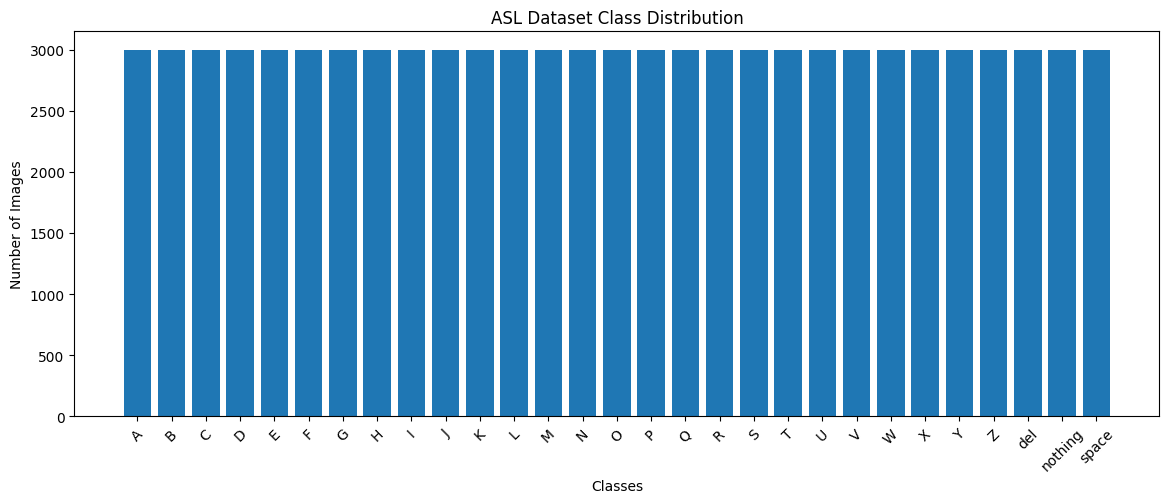

In [8]:
# Cell 7:  Bar chart of class distribution (balanced)
import matplotlib.pyplot as plt

class_counts = {}

for class_name in sorted(classes):

    class_path = os.path.join(
        train_path,
        class_name
    )

    class_counts[class_name] = len(
        os.listdir(class_path)
    )

plt.figure(figsize=(14, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.title("ASL Dataset Class Distribution")

plt.xticks(rotation=45)
plt.show()

In [9]:
# Cell 8:  Check size and colour mode of one image (200x200, RGB)
from PIL import Image

sample_image_path = os.path.join(
    train_path,
    "A",
    os.listdir(os.path.join(train_path, "A"))[0]
)

img = Image.open(sample_image_path)

print("Image Size:", img.size)
print("Image Mode:", img.mode)

Image Size: (200, 200)
Image Mode: RGB


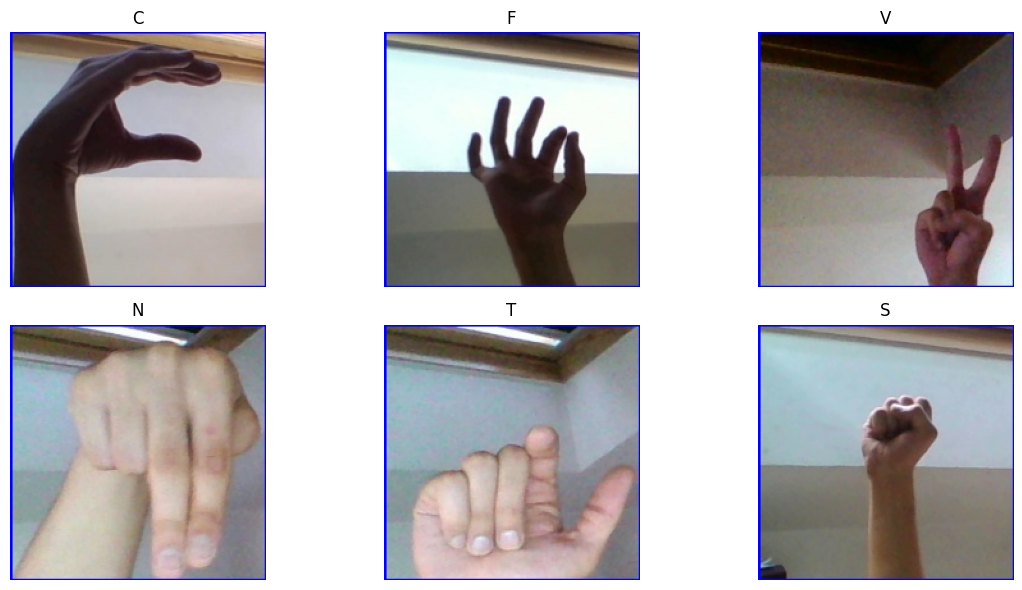

In [10]:
# Cell 9:  Show 6 random sample images
import random

plt.figure(figsize=(12, 6))

for i, class_name in enumerate(
    random.sample(classes, 6)
):

    class_path = os.path.join(
        train_path,
        class_name
    )

    image_name = random.choice(
        os.listdir(class_path)
    )

    image_path = os.path.join(
        class_path,
        image_name
    )

    img = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
# Cell 10: Check for invalid file types (0 found)
import os

valid_extensions = ('.jpg', '.jpeg', '.png')

invalid_files = []

for class_name in classes:

    class_path = os.path.join(
        train_path,
        class_name
    )

    for file_name in os.listdir(class_path):

        if not file_name.lower().endswith(valid_extensions):

            invalid_files.append(
                os.path.join(class_path, file_name)
            )

print("Total Invalid Files:", len(invalid_files))

print("Invalid Files:", invalid_files[:10])

Total Invalid Files: 0
Invalid Files: []


In [12]:
# Cell 11: Check for corrupted images (0 found)
from PIL import Image

corrupted_images = []

for class_name in classes:

    class_path = os.path.join(
        train_path,
        class_name
    )

    for file_name in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file_name
        )

        try:
            with Image.open(image_path) as img:
                img.verify()

        except Exception:
            corrupted_images.append(image_path)

print("Total Corrupted Images:", len(corrupted_images))

Total Corrupted Images: 0


In [13]:
# Cell 12: Check for exact duplicate images using MD5 hash (0 found)
import hashlib

image_hashes = {}

for class_name in classes:

    class_path = os.path.join(
        train_path,
        class_name
    )

    for file_name in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file_name
        )

        with open(image_path, "rb") as f:

            image_hash = hashlib.md5(
                f.read()
            ).hexdigest()

        if image_hash in image_hashes:

            image_hashes[image_hash].append(
                image_path
            )

        else:

            image_hashes[image_hash] = [
                image_path
            ]

duplicates = {
    key: value
    for key, value in image_hashes.items()
    if len(value) > 1
}

print("Duplicate Groups:", len(duplicates))

Duplicate Groups: 0


In [14]:
# Cell 13: Check image dimensions (all 200x200)
dimension_counts = {}

for class_name in classes:

    class_path = os.path.join(
        train_path,
        class_name
    )

    for file_name in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file_name
        )

        try:

            with Image.open(image_path) as img:

                size = img.size

                dimension_counts[size] = (
                    dimension_counts.get(size, 0) + 1
                )

        except Exception:
            pass

print("Image Dimensions Distribution:")

for size, count in dimension_counts.items():

    print(size, ":", count)

Image Dimensions Distribution:
(200, 200) : 87000


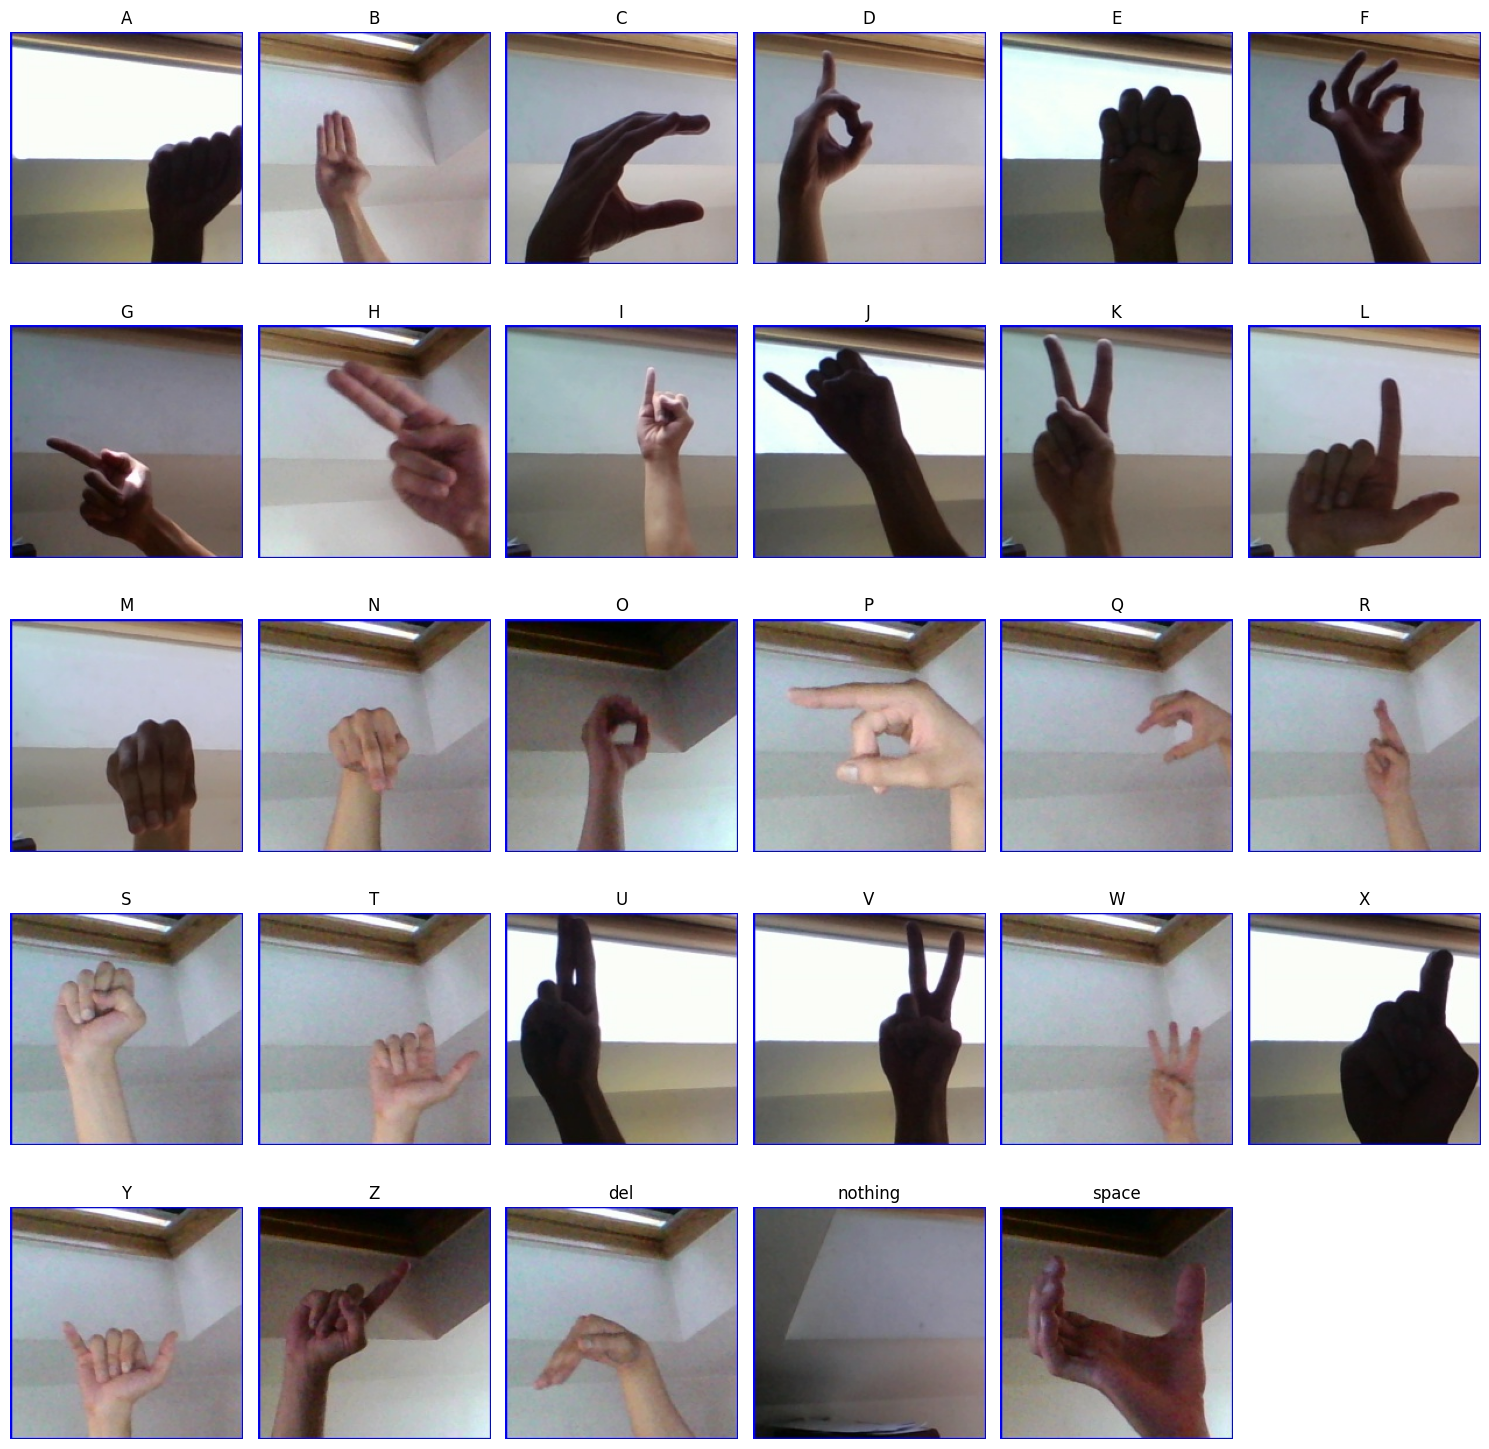

In [15]:
# Cell 14: Show one sample image from every class
import matplotlib.pyplot as plt
import os
import random
from PIL import Image

plt.figure(figsize=(15, 15))

for i, class_name in enumerate(sorted(classes)):

    class_path = os.path.join(
        train_path,
        class_name
    )

    image_name = random.choice(
        os.listdir(class_path)
    )

    image_path = os.path.join(
        class_path,
        image_name
    )

    img = Image.open(image_path)

    plt.subplot(5, 6, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
# Cell 15: Load the official test folder (only 28 images)
test_path = os.path.join(
    extract_path,
    "asl_alphabet_test",
    "asl_alphabet_test"
)

test_files = os.listdir(test_path)

print("Total Test Images:", len(test_files))

print("Test Image Names:")

for file in test_files[:15]:
    print(file)

Total Test Images: 28
Test Image Names:
Z_test.jpg
D_test.jpg
J_test.jpg
A_test.jpg
O_test.jpg
C_test.jpg
T_test.jpg
Q_test.jpg
F_test.jpg
M_test.jpg
S_test.jpg
B_test.jpg
I_test.jpg
H_test.jpg
nothing_test.jpg


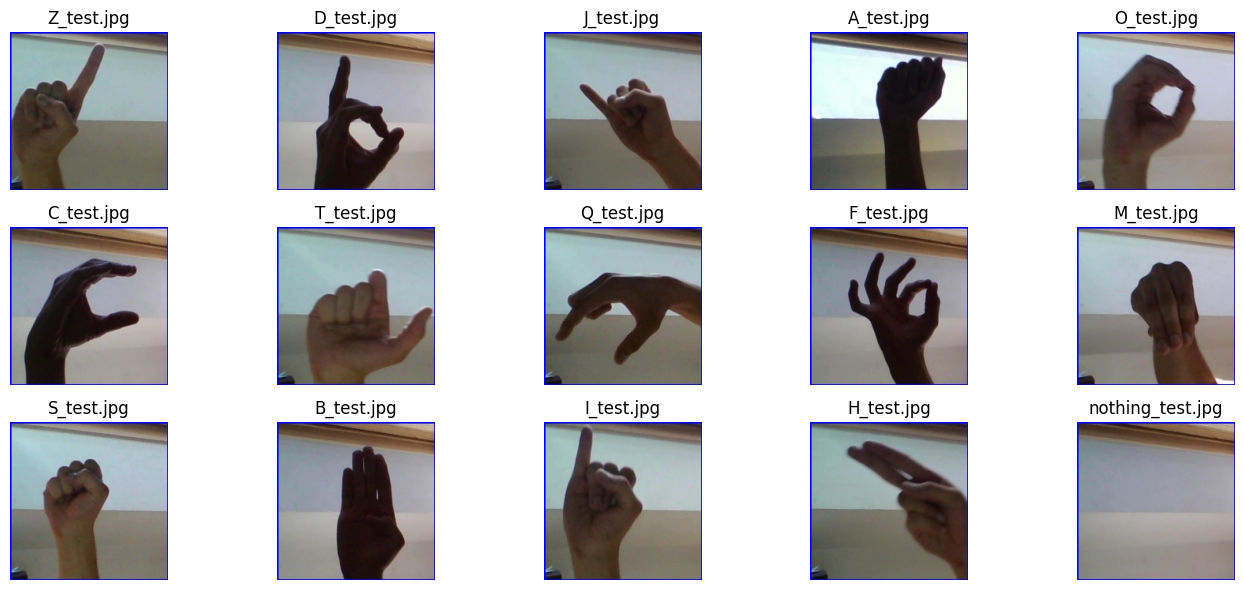

In [17]:
# Cell 16: Display the official test images
plt.figure(figsize=(14, 6))

for i, file_name in enumerate(test_files[:15]):

    image_path = os.path.join(
        test_path,
        file_name
    )

    img = Image.open(image_path)

    plt.subplot(3, 5, i + 1)
    plt.imshow(img)
    plt.title(file_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
# Cell 17: Split data into 70% train, 15% val, 15% test
!pip install split-folders
import splitfolders

# Stratified split: 70% train, 15% validation, 15% test
splitfolders.ratio(
    train_path,
    output="asl_split",
    seed=42,
    ratio=(0.7, 0.15, 0.15)
)

print("Split complete! Check 'asl_split' folder.")

Copying files: 87000 files [00:15, 5643.10 files/s]

Split complete! Check 'asl_split' folder.


In [19]:
# Cell 18: Verify the split counts
import os

split_path = "asl_split"

for folder in ["train", "val", "test"]:
    folder_path = os.path.join(split_path, folder)
    total_images = 0
    for class_name in os.listdir(folder_path):
        class_path = os.path.join(folder_path, class_name)
        count = len(os.listdir(class_path))
        total_images += count
    print(f"{folder}: {total_images} images across {len(os.listdir(folder_path))} classes")

train: 60900 images across 29 classes
val: 13050 images across 29 classes
test: 13050 images across 29 classes


In [20]:
# Cell 19: Preprocessing: resize to 64x64 and normalize (rescale 1/255)
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = 64
batch_size = 32

train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    "asl_split/train",
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode="categorical"
)

val_generator = val_datagen.flow_from_directory(
    "asl_split/val",
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode="categorical"
)

test_generator = test_datagen.flow_from_directory(
    "asl_split/test",
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode="categorical"
)

print("Preprocessing setup complete!")
print("Class indices:", train_generator.class_indices)

Found 60900 images belonging to 29 classes.
Found 13050 images belonging to 29 classes.
Found 13050 images belonging to 29 classes.
Preprocessing setup complete!
Class indices: {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'J': 9, 'K': 10, 'L': 11, 'M': 12, 'N': 13, 'O': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'U': 20, 'V': 21, 'W': 22, 'X': 23, 'Y': 24, 'Z': 25, 'del': 26, 'nothing': 27, 'space': 28}


In [21]:
# Cell 20: Extract HOG features from 24 letters (J and Z excluded)
import os, random
import cv2
import numpy as np
from skimage.feature import hog

selected_classes = list("ABCDEFGHIKLMNOPQRSTUVWXY")
train_dir = "asl_split/train"
images_per_class = 500

X = []
y = []

for class_name in selected_classes:
    class_path = os.path.join(train_dir, class_name)
    all_files = sorted(os.listdir(class_path))
    selected_files = random.Random(42).sample(all_files, images_per_class)

    for file_name in selected_files:
        img = cv2.imread(os.path.join(class_path, file_name), cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (64, 64))
        features = hog(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
        X.append(features)
        y.append(class_name)

X = np.array(X)
y = np.array(y)

np.save("X_hog.npy", X)
np.save("y_hog.npy", y)

print("Done! X shape:", X.shape)

Done! X shape: (12000, 1764)


In [22]:
# Cell 21: Train SVM and Random Forest on HOG features
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
print("\nSVM Accuracy:", accuracy_score(y_test, svm_pred))

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

Training samples: 9600
Testing samples: 2400

SVM Accuracy: 0.9008333333333334
Random Forest Accuracy: 0.8829166666666667


In [23]:
# Cell 22: Create CNN data generators for 24 classes
from tensorflow.keras.preprocessing.image import ImageDataGenerator

selected_classes = list("ABCDEFGHIKLMNOPQRSTUVWXY")
img_size = 64
batch_size = 32

datagen = ImageDataGenerator(rescale=1./255)

train_gen = datagen.flow_from_directory(
    "asl_split/train", target_size=(img_size, img_size),
    batch_size=batch_size, class_mode="categorical",
    classes=selected_classes
)

val_gen = datagen.flow_from_directory(
    "asl_split/val", target_size=(img_size, img_size),
    batch_size=batch_size, class_mode="categorical",
    classes=selected_classes
)

test_gen = datagen.flow_from_directory(
    "asl_split/test", target_size=(img_size, img_size),
    batch_size=batch_size, class_mode="categorical",
    classes=selected_classes, shuffle=False
)

Found 50400 images belonging to 24 classes.
Found 10800 images belonging to 24 classes.
Found 10800 images belonging to 24 classes.


In [24]:
# Cell 23: Build the CNN architecture
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(24, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 686,296 (2.62 MB)

 Trainable params: 686,296 (2.62 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# Cell 24: Train the CNN with early stopping and checkpoint, then evaluate
from google.colab import drive
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import os

drive.mount('/content/drive')
save_dir = "/content/drive/MyDrive/VisionForge"
os.makedirs(save_dir, exist_ok=True)

callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    ModelCheckpoint(f"{save_dir}/asl_cnn_best.keras", monitor="val_accuracy", save_best_only=True)
]

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,
    callbacks=callbacks
)

test_loss, test_acc = model.evaluate(test_gen)
print("\nCNN Test Accuracy:", test_acc)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/15
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 63s 35ms/step - accuracy: 0.5218 - loss: 1.4493 - val_accuracy: 0.8839 - val_loss: 0.3959
Epoch 2/15
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 48s 30ms/step - accuracy: 0.8362 - loss: 0.4558 - val_accuracy: 0.9643 - val_loss: 0.1276
Epoch 3/15
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 49s 31ms/step - accuracy: 0.9053 - loss: 0.2637 - val_accuracy: 0.9861 - val_loss: 0.0539
Epoch 4/15
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 52s 33ms/step - accuracy: 0.9353 - loss: 0.1802 - val_accuracy: 0.9920 - val_loss: 0.0360
Epoch 5/15
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 52s 33ms/step - accuracy: 0.9530 - loss: 0.1355 - val_accuracy: 0.9959 - val_loss: 0.0176
Epoch 6/15
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 48s 31ms/step - accuracy: 0.9613 - loss: 0.1101 - val_accuracy: 0.9956 - val_loss: 0.0159
Epoch 7/15
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 50s 31ms/step - accuracy: 0.9669 - lo

In [26]:
# Cell 25: Predict one random test image per letter
import os, random
import numpy as np
from tensorflow.keras.preprocessing import image

labels = list(train_gen.class_indices.keys())
correct = 0

for letter in labels:
    # pick one random test image of this letter
    folder = f"asl_split/test/{letter}"
    file = random.choice(os.listdir(folder))

    # load and prepare the image
    img = image.load_img(os.path.join(folder, file), target_size=(64, 64))
    arr = np.expand_dims(image.img_to_array(img) / 255.0, axis=0)

    # model prediction
    pred = model.predict(arr, verbose=0)
    predicted = labels[np.argmax(pred)]
    confidence = np.max(pred) * 100

    result = "CORRECT" if predicted == letter else "WRONG"
    correct += (predicted == letter)
    print(f"Actual: {letter}  |  Predicted: {predicted}  |  Confidence: {confidence:.1f}%  |  {result}")

print(f"\nTotal: {correct} / {len(labels)} correct")

Actual: A  |  Predicted: A  |  Confidence: 100.0%  |  CORRECT
Actual: B  |  Predicted: B  |  Confidence: 100.0%  |  CORRECT
Actual: C  |  Predicted: C  |  Confidence: 100.0%  |  CORRECT
Actual: D  |  Predicted: D  |  Confidence: 100.0%  |  CORRECT
Actual: E  |  Predicted: E  |  Confidence: 100.0%  |  CORRECT
Actual: F  |  Predicted: F  |  Confidence: 100.0%  |  CORRECT
Actual: G  |  Predicted: G  |  Confidence: 100.0%  |  CORRECT
Actual: H  |  Predicted: H  |  Confidence: 100.0%  |  CORRECT
Actual: I  |  Predicted: I  |  Confidence: 100.0%  |  CORRECT
Actual: K  |  Predicted: K  |  Confidence: 100.0%  |  CORRECT
Actual: L  |  Predicted: L  |  Confidence: 100.0%  |  CORRECT
Actual: M  |  Predicted: M  |  Confidence: 100.0%  |  CORRECT
Actual: N  |  Predicted: N  |  Confidence: 100.0%  |  CORRECT
Actual: O  |  Predicted: O  |  Confidence: 99.9%  |  CORRECT
Actual: P  |  Predicted: P  |  Confidence: 100.0%  |  CORRECT
Actual: Q  |  Predicted: Q  |  Confidence: 100.0%  |  CORRECT
Actual: R

Accuracy : 0.9994
Macro F1 : 0.9994

Classification Report:

              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       450
           B     1.0000    0.9933    0.9967       450
           C     1.0000    1.0000    1.0000       450
           D     1.0000    0.9978    0.9989       450
           E     0.9934    1.0000    0.9967       450
           F     1.0000    1.0000    1.0000       450
           G     0.9978    1.0000    0.9989       450
           H     1.0000    0.9978    0.9989       450
           I     1.0000    1.0000    1.0000       450
           K     1.0000    1.0000    1.0000       450
           L     1.0000    1.0000    1.0000       450
           M     1.0000    1.0000    1.0000       450
           N     1.0000    1.0000    1.0000       450
           O     0.9978    1.0000    0.9989       450
           P     1.0000    1.0000    1.0000       450
           Q     1.0000    1.0000    1.0000       450
           R     1.0

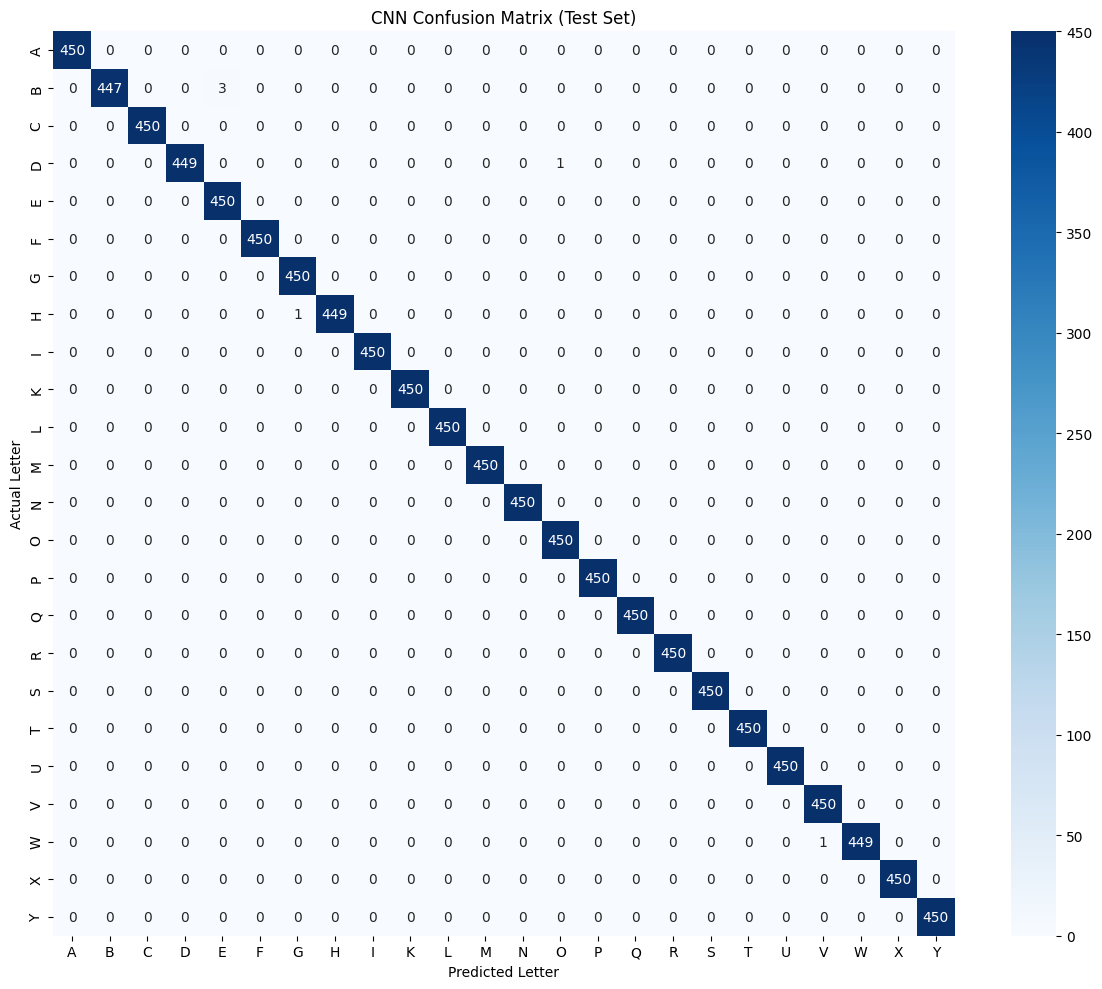

In [27]:
# Cell 26: Classification report and confusion matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# predictions on the test set
y_prob = model.predict(test_gen, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = test_gen.classes
class_names = list(test_gen.class_indices.keys())

# overall scores
print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
print("Macro F1 :", round(f1_score(y_true, y_pred, average="macro"), 4))

# precision, recall, F1 for every letter
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Letter")
plt.ylabel("Actual Letter")
plt.title("CNN Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/VisionForge/cnn_confusion_matrix.png", dpi=150)
plt.show()

In [28]:
# Cell 27: Compare SVM, Random Forest and CNN metrics
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

results = pd.DataFrame({
    "SVM (HOG)": scores(y_test, svm_model.predict(X_test)),
    "Random Forest (HOG)": scores(y_test, rf_model.predict(X_test)),
    "CNN": scores(y_true, y_pred),
}).T

results = (results * 100).round(2)
print(results)

results.to_csv("/content/drive/MyDrive/VisionForge/model_comparison.csv")

                     Accuracy  Precision (macro)  Recall (macro)  \
SVM (HOG)               90.08              90.21           90.08   
Random Forest (HOG)     88.29              88.52           88.29   
CNN                     99.94              99.94           99.94   

                     F1-score (macro)  
SVM (HOG)                       90.10  
Random Forest (HOG)             88.28  
CNN                             99.94  


In [29]:
# Cell 28: Print the final comparison table
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

print(results)

                     Accuracy  Precision (macro)  Recall (macro)  F1-score (macro)
SVM (HOG)               90.08              90.21           90.08             90.10
Random Forest (HOG)     88.29              88.52           88.29             88.28
CNN                     99.94              99.94           99.94             99.94
